# CardioFusion-XAI — EchoNet-Dynamic temporal explainability

This notebook uses the trained PanEcho model and a real EchoNet-Dynamic test video to perform temporal-window occlusion. It measures how the EF output changes when consecutive video-frame windows are replaced by a median-frame baseline.

This is a perturbation explanation, not SHAP, not anatomical localization and not a causal explanation. It does not turn EF into a disease probability.

In [1]:
from pathlib import Path
import os
import sys


def find_ml_service_root(start=None):
    current = Path(start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "pyproject.toml").is_file() and (candidate / "src").is_dir() and (candidate / "config").is_dir():
            return candidate
    raise FileNotFoundError(
        "Could not locate ml-service/. Start Jupyter from the repository or from ml-service/."
    )


ML_ROOT = find_ml_service_root()
os.chdir(ML_ROOT)
if str(ML_ROOT) not in sys.path:
    sys.path.insert(0, str(ML_ROOT))
print(f"ML project root: {ML_ROOT}")

ML project root: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service


## 1. Locate the EchoNet-Dynamic test video and load PanEcho

Accepted source layouts:

- Raw EchoNet: `data/raw/echo/echonet/FileList.csv` and `Videos/`.
- Project manifest: `data/processed/echo/echonet/echonet_manifest.csv`.

In [2]:
import numpy as np
import pandas as pd
from src.datasets.panecho_echonet_dataset import load_echonet_records
from src.echo_processing.panecho_reader import read_echo_for_panecho
from src.inference.model_manager import ModelManager
from src.xai.echo_explainer import temporal_occlusion_explanation

models = ModelManager(ML_ROOT)
if models.echo_model is None or models.echo_backend != "panecho":
    raise FileNotFoundError("A PanEcho checkpoint is required. Verify checkpoints/echo/panecho/panecho_echonet_finetuned.pt or configure a pretrained checkpoint.")
manifest = ML_ROOT / "data/processed/echo/echonet/echonet_manifest.csv"
raw_root = ML_ROOT / "data/raw/echo/echonet"
if manifest.is_file():
    records = load_echonet_records(manifest=manifest, project_root=ML_ROOT)
elif (raw_root / "FileList.csv").is_file():
    records = load_echonet_records(data_root=raw_root)
else:
    raise FileNotFoundError("EchoNet manifest/FileList.csv is missing. Run notebooks/02_preprocessing/03_echonet_dynamic_preprocessing.ipynb or install the raw EchoNet-Dynamic files.")
records = records[records["split"].eq("test")].reset_index(drop=True)
if records.empty:
    raise ValueError("EchoNet manifest has no test-split videos.")
video_path = __import__("pathlib").Path(records.iloc[0]["video_path"])
if not video_path.is_absolute():
    video_path = ML_ROOT / video_path
if not video_path.is_file():
    raise FileNotFoundError(f"EchoNet video is missing: {video_path}")
print("Selected test video:", video_path)

Selected test video: D:\Programming\VS Code\Projects\CardioFusion-XAI\ml-service\data\raw\echo\echonet\Videos\0X100CF05D141FF143.avi


## 2. Decode the video using the PanEcho preprocessing contract

In [3]:
clips, video_metadata = read_echo_for_panecho(video_path, file_format=video_path.suffix.lstrip("."), num_clips=models.echo_num_clips)
print("Clip tensor:", tuple(clips.shape))
print("Video metadata:", video_metadata)

Clip tensor: (4, 3, 16, 224, 224)
Video metadata: {'fps': 50.0, 'reported_frames': 248, 'decoded_frames': 248, 'source_width': 112, 'source_height': 112, 'format': 'AVI', 'clip_len': 16, 'num_clips': 4, 'frames_used': 64, 'short_video_padded': False}


## 3. Perform temporal occlusion

The prediction function accepts the same `[number_of_clips, 3, 16, 224, 224]` tensor shape as the production PanEcho inference method. The explainer converts Torch tensors safely to CPU arrays before perturbation.

In [4]:
import torch
from src.models.echo.panecho import decode_outputs


def predict_ef_from_clips(array: np.ndarray) -> float:
    tensor = torch.as_tensor(array, dtype=torch.float32, device=models.device)
    with torch.inference_mode():
        outputs = models.echo_model.predict_clips(tensor)
        decoded = decode_outputs(outputs)
    return float(decoded["EF"]["value"])

clips_np = clips.detach().cpu().numpy().astype(np.float32)
explanation = temporal_occlusion_explanation(predict_ef_from_clips, clips_np, window_frames=4)
print("Baseline EF:", explanation["original_output"])
print("Explanation:", explanation["method"])

Baseline EF: 57.28301239013672
Explanation: temporal_window_occlusion


## 4. Plot the temporal contribution pattern

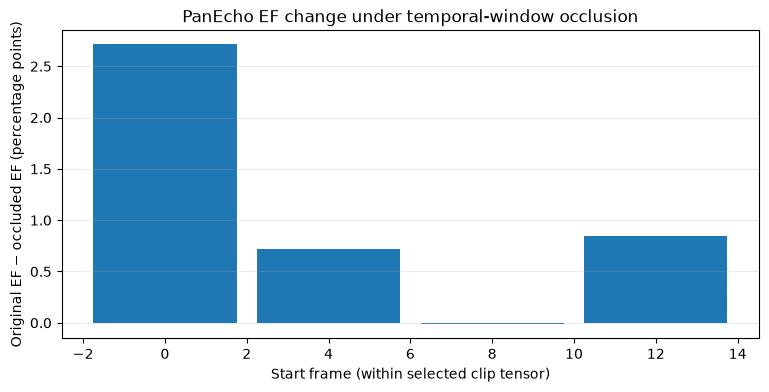

In [5]:
import matplotlib.pyplot as plt

windows = explanation["windows"]
starts = [item["start_frame"] for item in windows]
differences = [item["output_difference"] for item in windows]
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(starts, differences, width=3.5)
ax.set_title("PanEcho EF change under temporal-window occlusion")
ax.set_xlabel("Start frame (within selected clip tensor)")
ax.set_ylabel("Original EF − occluded EF (percentage points)")
ax.grid(axis="y", alpha=0.25)
plt.show()

## 5. Interpretation limits

- Occlusion scores depend on the chosen median-frame baseline and window size.
- A large output difference does not establish a causal anatomical region.
- Report stability across multiple test videos and multiple window sizes.
- EF remains a continuous measurement; it must not be rendered as a disease probability.
- Use clinically reviewed heatmaps and other methods as complementary evidence, not as a substitute for image interpretation.